In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad, solve_bvp
from scipy.interpolate import CubicSpline
from numba import jit, njit, prange
plt.style.use("emilie_style.mplstyle")
colors = mpl.rcParams["axes.prop_cycle"].by_key()["color"]


In [3]:
def simulate_mean_field_euler(initial_conditions, in_, out_, activate, deactivate, absorb, reinjection=0, dt=0.01, ts=1.0, tmax=10.0):
    """Simulate the five-state system in the mean-field approximation with the Euler method.

    Adding a (partially) absorbing reaction channel to the system only accecible from the p_in_A state. 
    Adding reinjection of particles into the system after absorption. Reinjection allows for a non-zero steady state to be reached.
    The reinjection parameter is either 0 (no reinjection) or 1 (full reinjection). The reinjection term is added to the p_out_N compartment.
    
    The state vector is ordered as (t, p_in_A, p_in_N, p_out_A, p_out_N, p_t).
    """

    p_in_A, p_in_N, p_out_A, p_out_N, p_t = initial_conditions
    click = 0
    t = 0
    saved = np.zeros((int(tmax / ts + 1), 6)) # t, p_in_A, p_in_N, p_out_A, p_out_N, p_t

    saved[click, :] = [t, p_in_A, p_in_N, p_out_A, p_out_N, p_t]
    click += 1
    t += dt

    # Check reinjection parameter
    if reinjection not in [0, 1]:
        raise ValueError("reinjection parameter must be either 0 (no reinjection) or 1 (full reinjection)")

    while t < tmax:
        dp_in_A = in_ * p_out_A - (deactivate + out_ + absorb) * p_in_A
        dp_in_N = in_ * p_out_N + deactivate * p_in_A - out_ * p_in_N
        dp_out_A = out_ * p_in_A + activate * p_out_N - (deactivate + in_) * p_out_A
        dp_out_N = out_ * p_in_N + deactivate * p_out_A - (activate + in_) * p_out_N + reinjection * absorb * p_in_A
        dp_t = absorb * p_in_A

        p_in_A += dp_in_A * dt
        p_in_N += dp_in_N * dt
        p_out_A += dp_out_A * dt
        p_out_N += dp_out_N * dt
        p_t += dp_t * dt
        t += dt

        if t >= click * ts:
            saved[click, :] = [t, p_in_A, p_in_N, p_out_A, p_out_N, p_t]
            click += 1

    return saved

In [4]:
def simulate_mean_field_gillespie(initial_conditions, in_, out_, activate, deactivate, absorb, reinjection, ts, tmax, n_particles=1000, rng=None):
    """Simulate the five-state system with the Gillespie algorithm.

    Adding a (partially) absorbing reaction channel to the system only accecible from the p_in_A state. 
    Adding reinjection of particles into the system after absorption. Reinjection allows for a non-zero steady state to be reached.
    The reinjection parameter is either 0 (no reinjection) or 1 (full reinjection). The reinjection term is added to the p_out_N compartment.

    The state vector is ordered as (t, p_in_A, p_in_N, p_out_A, p_out_N, p_t).
    The returned values are normalized by the total number of particles so
    downstream code can continue to interpret them as probabilities.
    """
    
    p_in_A, p_in_N, p_out_A, p_out_N, p_t = initial_conditions

    if rng is None:
        rng = np.random.default_rng()

    counts = np.array([p_in_A, p_in_N, p_out_A, p_out_N, p_t], dtype=float)
    total = counts.sum()
    if total <= 0:
        raise ValueError("initial_conditions must contain a positive total mass")

    # Check reinjection parameter
    if reinjection not in [0, 1]:
        raise ValueError("reinjection parameter must be either 0 (no reinjection) or 1 (full reinjection)")

    counts = np.rint(counts / total * n_particles).astype(int) # Convert probabilities to integer counts
    counts[1] += n_particles - counts.sum() # Adjust the second compartment to ensure the total number of particles is correct

    save_times = np.arange(0.0, tmax + ts, ts)
    saved = np.zeros((len(save_times), 6))
    saved[0, :] = [0.0, *(counts / n_particles)]

    t = 0.0
    save_index = 1

    def record_until(current_time):
        nonlocal save_index
        while save_index < len(save_times) and current_time >= save_times[save_index]:
            saved[save_index, :] = [save_times[save_index], *(counts / n_particles)]
            save_index += 1

    record_until(t)

    while t < tmax and save_index < len(save_times):
        a1 = out_ * counts[0]
        a2 = out_ * counts[1]
        a3 = in_ * counts[2]
        a4 = in_ * counts[3]
        a5 = deactivate * counts[0]
        a6 = deactivate * counts[2]
        a7 = activate * counts[3]
        a8 = absorb * counts[0]

        propensities = np.array([a1, a2, a3, a4, a5, a6, a7, a8], dtype=float)
        a0 = propensities.sum()

        if a0 <= 0:
            break

        t += -np.log(rng.random()) / a0
        record_until(t)

        if t > tmax:
            break

        # Break if everything is absorbed and reinjection is not allowed
        if counts[0] == 0 and counts[1] == 0 and counts[2] == 0 and counts[3] == 0 and reinjection == 0:
            break

        # With reinjection, the number of particles in the system can exceed n_particles, so we don't enforce a hard limit on the total number of particles.
        n_particles = counts.sum()  # Update the total number of particles in the system

        threshold = rng.random() * a0
        cumulative = 0.0

        if threshold < (cumulative := cumulative + a1): # p_in_A -> p_out_A
            counts[0] -= 1
            counts[2] += 1
        elif threshold < (cumulative := cumulative + a2): # p_in_N -> p_out_N
            counts[1] -= 1
            counts[3] += 1
        elif threshold < (cumulative := cumulative + a3): # p_out_A -> p_in_A
            counts[2] -= 1
            counts[0] += 1
        elif threshold < (cumulative := cumulative + a4): # p_out_N -> p_in_N
            counts[3] -= 1
            counts[1] += 1
        elif threshold < (cumulative := cumulative + a5): # p_in_A -> p_in_N
            counts[0] -= 1
            counts[1] += 1
        elif threshold < (cumulative := cumulative + a6): # p_out_A -> p_out_N
            counts[2] -= 1
            counts[3] += 1
        elif threshold < (cumulative := cumulative + a7): # p_out_N -> p_out_A
            counts[3] -= 1
            counts[2] += 1
        else: # p_in_A -> p_t (absorption)
            counts[0] -= 1
            counts[4] += 1
            counts[3] += 1 * reinjection


    while save_index < len(save_times):
        saved[save_index, :] = [save_times[save_index], *(counts / n_particles)]
        save_index += 1

    return saved

In [15]:
# ________________________________________________________________
# Two-state model Backward Kolmogorov equations solver
# _______________________________________________________________

def compute_for_two_state(
    r_target,
    rf,
    rn,
    A,
    b,
    D0,
    Dn,
    lam=1.0,
    gamma=0.1,
    activation_outside=1,
    ndim=3,
    N=4000,
    tol=1e-4,
    max_nodes=20000,
):
    """
    Computes both T_A(r) and T_I(r) for the two-state model.

    Active state:
        -1 = LT_A - gamma * (T_A - T_I)
        T_A(r_target) = 0
        T_A'(rn) = 0

    Inactive state:
        -1 = LT_I - lambda(r) * (T_I - T_A)
        T_I'(r_target) = 0
        T_I'(rn) = 0

    where L is the generator of the diffusion process:
        Lf = D(r) f'' + mu(r) f'

    Parameters
    ----------
    r_target : float
        Target radius.
    rf : float
        Droplet radius (where the sigmoidal functions are centered).
    rn : float
        Outer reflecting boundary radius.
    A : float
        Amplitude of the sigmoidal function for the potential U(r).
    b : float
        Steepness of the sigmoidal function for the potential U(r).
    D0 : float
        Diffusion coefficient inside the droplet (r < rf).
    Dn : float
        Diffusion coefficient outside the droplet (r > rf).
    lam : float, optional
        Maximum activation rate (default 1.0).
    gamma : float, optional
        Deactivation rate (default 0.1).
    activation_outside : int, optional
        If 1, activation occurs outside the droplet; if 0, inside (default 1).
    ndim : int, optional
        Spatial dimension (default 3).
    N : int, optional
        Number of spatial grid points.
    tol : float, optional
        Tolerance for the solution (default 1e-4).
    max_nodes : int, optional
        Maximum number of nodes for the solver (default 20000).


    Returns
    -------
    TA_func : callable
        Interpolating function for T_A(r).
    TI_func : callable
        Interpolating function for T_I(r).
    out : dict
        Diagnostics and raw arrays.
    """

    # ------------------------------------------------------------
    # Define U(r), D(r), and related functions
    # ------------------------------------------------------------

    def sig(rr):
        """1/(1+exp(-b(r-rf))): 0 deep inside the condensate, 1 well outside."""
        return 1.0 / (1.0 + np.exp(-b * (rr - rf)))

    def dsig(rr):
        e = np.exp(-b * (rr - rf))
        return b * e / (1.0 + e) ** 2
    
    def D_func(rr):
        return D0 + (Dn - D0) * sig(rr)

    def mu_func(rr):
        s  = sig(rr)
        ds = dsig(rr)
        D  = D0 + (Dn - D0) * s
        return (ndim - 1) * D / rr + (Dn - D0) * ds - D * A * ds

    def lambda_func(rr):
        """Activation rate. Control whether activation occurs inside or outside the condensate."""
        s = sig(rr)
        if activation_outside == 1:
            return lam * s
        return lam * (1.0 - s)


    # ============================================================
    # BVP system
    # ============================================================
    # Unknown vector:
    # y[0] = T_A
    # y[1] = T_A'
    # y[2] = T_I
    # y[3] = T_I'

    def ode_system(r, y):
        TA, dTA, TI, dTI = y

        D = D_func(r)
        mu = mu_func(r)
        lam = lambda_func(r)

        # From:
        # -1 = mu dTA + D d2TA - gamma (TA - TI)
        # -1 = mu dTI + D d2TI - lambda(r) (TI - TA)
        #
        # Therefore:
        # d2TA = [ -1 - mu dTA + gamma (TA - TI) ] / D
        # d2TI = [ -1 - mu dTI + lambda(r) (TI - TA) ] / D

        ddTA = (-1.0 - mu * dTA + gamma * (TA - TI)) / D
        ddTI = (-1.0 - mu * dTI + lam   * (TI - TA)) / D

        return np.vstack((dTA, ddTA, dTI, ddTI))

    def bc(ya, yb):
        """
        Boundary conditions:
        T_A(r_target)   = 0
        T_A'(rn)  = 0
        T_I'(r_target)  = 0
        T_I'(rn)  = 0
        """
        return np.array([
            ya[0],      # T_A(r_target) = 0
            yb[1],      # T_A'(rn) = 0
            ya[3],      # T_I'(r_target) = 0
            yb[3],      # T_I'(rn) = 0
        ])
    
    # ============================================================
    # Initial mesh and guess
    # ============================================================

    r_mesh = np.linspace(r_target, rn, N)

    # A simple initial guess:
    L = rn - r_target
    x = (r_mesh - r_target) / L

    TA_guess = L**2 * (2*x - x**2)   # TA(r_target)=0, TA'(rn)=0
    dTA_guess = 2*L*(1 - x)

    TI_guess = np.full_like(r_mesh, L**2)   # constant => derivative zero at both ends
    dTI_guess = np.zeros_like(r_mesh)

    y_guess = np.vstack((TA_guess, dTA_guess, TI_guess, dTI_guess))

    # ============================================================
    # Solve the boundary value problem
    # ============================================================

    sol = solve_bvp(ode_system, bc, r_mesh, y_guess, tol=tol, max_nodes=max_nodes)

    if not sol.success:
        raise RuntimeError(f"BVP solver failed: {sol.message}")
   
    # ============================================================
    # Evaluate and interpolate solutions
    # ============================================================
        
    r_eval = np.linspace(r_target, rn, 1000)
    TA_sol = sol.sol(r_eval)[0]
    TI_sol = sol.sol(r_eval)[2]

    TA_spline = CubicSpline(r_eval, TA_sol, bc_type="natural", extrapolate=False)
    TI_spline = CubicSpline(r_eval, TI_sol, bc_type="natural", extrapolate=False)
    
    def TA_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TA_spline(r)

    def TI_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TI_spline(r)

    out = {
        "r_grid": r_eval,
        "TA_values": TA_sol,
        "TI_values": TI_sol,
        "TA_rn": float(TA_spline(rn)),
        "TI_rn": float(TI_spline(rn)),
        "drift": mu_func(r_eval),
        "lambda_values": lambda_func(r_eval),
    }

    return TA_func, TI_func, out

In [5]:
def p_out_definition(V_out, V_in, A):
    return V_out / (V_out + V_in * np.exp(A))

def permeability(D, delta, A0):
    return D / (delta * (1 + np.exp(A0)))

def rates_from_permeability(A0, rf, rn, D, delta):
    V_in = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in
    S = 4 * np.pi * rf**2
    P = permeability(D, delta, A0)

    in_rate = S * P / V_out * np.exp(A0)
    out_rate = S * P / V_in * np.ones_like(A0)
    return in_rate, out_rate

def rates_from_mfpt(A0, rf, rn, D):
    in_rate = 3 * D * rf / rn**3 * np.ones_like(A0)
    out_rate = in_rate * (rn**3 - rf**3) / rf**3 * np.exp(-A0)
    return (in_rate, out_rate)

def absorbtion_rate(rt, rf, D, kappa):
    absorbtion_rate = 3 * rt / rf**3 * (D + kappa * rt)
    return absorbtion_rate

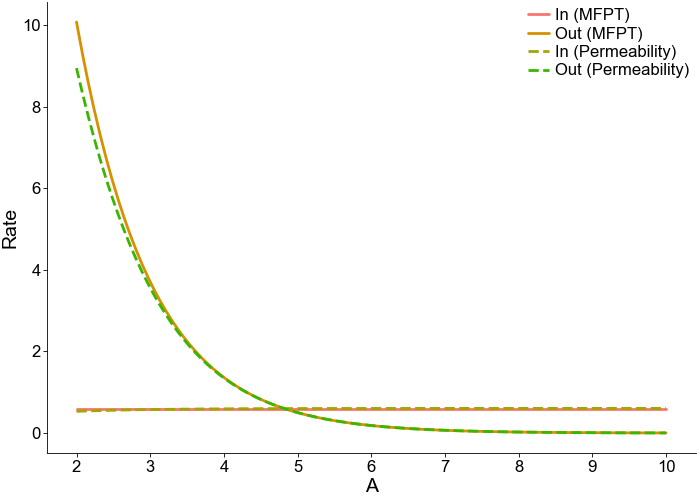

In [6]:
# Calculate in and out rates based on the MFPT and the permability and compare the two methods
A_vals = np.linspace(2, 10, 100)
rt = 0.01
rf = 0.2
rn = 1.0
D = 1.0
delta = rf  # Assuming delta is equal to the inner radius for this example
kappa = 0.1  # Assuming kappa is 0.1 for this example

in_from_mfpt, out_from_mfpt = rates_from_mfpt(A_vals, rf, rn, D)
in_from_perm, out_from_perm = rates_from_permeability(A_vals, rf, rn, D, delta)

plt.figure()
plt.plot(A_vals, in_from_mfpt, label='In (MFPT)')
plt.plot(A_vals, out_from_mfpt, label='Out (MFPT)')
plt.plot(A_vals, in_from_perm, ls='--', label='In (Permeability)')
plt.plot(A_vals, out_from_perm, ls='--', label='Out (Permeability)')
plt.xlabel('A')
plt.ylabel('Rate')
plt.legend()
plt.show()



In [105]:
# System parameters
A0 = 5.0
b = 1000.0
D = 0.1
rt = 0.01
rf = 0.2
rn = 2.0
delta = rf
kappa = 0

V_in = 4.0 / 3.0 * np.pi * rf**3
V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in

# Rates
in_rate, out_rate = rates_from_mfpt(A0, rf, rn, D)
activation_rate = 1.0
deactivation_rate = 0.1
absorb = absorbtion_rate(rt, rf, D, kappa)  # Assuming kappa is 0.1 for this example

print(f"in_rate: {in_rate:.2f}, out_rate: {out_rate:.2f}, \nactivation_rate: {activation_rate:.2f}, deactivation_rate: {deactivation_rate:.2f}")
print(f"absorbtion_rate: {absorb:.2f}")

# Initial conditions
p0_out = p_out_definition(V_out, V_in, A0)
p0_in = 1.0 - p0_out

p0_in_active, p0_out_active = 0.0, 0.0  
p0_in_neutral, p0_out_neutral = p0_in, p0_out  # All particles start in the neutral state, either inside or outside the droplet

initial_conditions = (p0_in_active, p0_in_neutral, p0_out_active, p0_out_neutral, 0.0)  # p_t starts at 0

in_rate: 0.01, out_rate: 0.05, 
activation_rate: 1.00, deactivation_rate: 0.10
absorbtion_rate: 0.37


In [106]:
tmax = 150

# Simulate deterministic mean-field model
dt = 0.001  # Simulation parameters
ts = 0.01 

reinjection = 0  # Assuming a reinjection rate of 0.1 for this example
saved_euler = simulate_mean_field_euler(initial_conditions, in_rate, out_rate, activation_rate, deactivation_rate, absorb, reinjection, dt, ts, tmax)


# Simulate the mean-field model using the Gillespie algorithm
n_particles = 500   # Simulation parameters
ts = 0.01 

saved_gillespie = simulate_mean_field_gillespie(initial_conditions, in_rate, out_rate, activation_rate, deactivation_rate, absorb, reinjection, ts, tmax, n_particles, rng=None)

In [114]:
# Define the time array and the probabilities for the Euler method simulation

t_euler = saved_euler[:, 0]

p_in_A_euler = saved_euler[:, 1]    # Local probabilities
p_in_N_euler = saved_euler[:, 2]
p_out_A_euler = saved_euler[:, 3]
p_out_N_euler = saved_euler[:, 4]
p_t_euler = saved_euler[:, 5]

p_in_euler = p_in_A_euler + p_in_N_euler    # Global probabilities
p_out_euler = p_out_A_euler + p_out_N_euler
p_A_euler = p_in_A_euler + p_out_A_euler
p_N_euler = p_in_N_euler + p_out_N_euler


# Define the time array and the probabilities for the Gillespie simulation
t_gillespie = saved_gillespie[:, 0]

p_in_A_gillespie = saved_gillespie[:, 1]
p_in_N_gillespie = saved_gillespie[:, 2]
p_out_A_gillespie = saved_gillespie[:, 3]
p_out_N_gillespie = saved_gillespie[:, 4]
p_t_gillespie = saved_gillespie[:, 5]

p_in_gillespie = p_in_A_gillespie + p_in_N_gillespie
p_out_gillespie = p_out_A_gillespie + p_out_N_gillespie
p_A_gillespie = p_in_A_gillespie + p_out_A_gillespie
p_N_gillespie = p_in_N_gillespie + p_out_N_gillespie


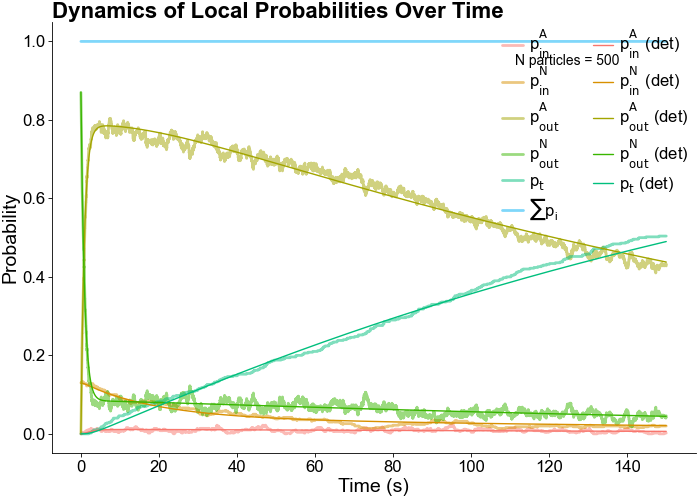

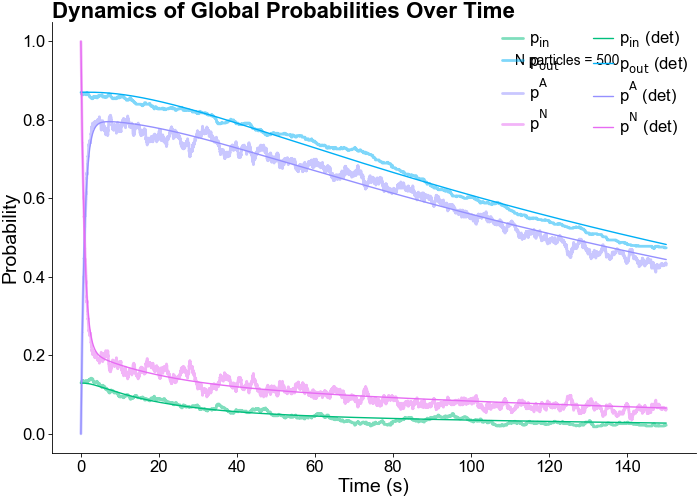

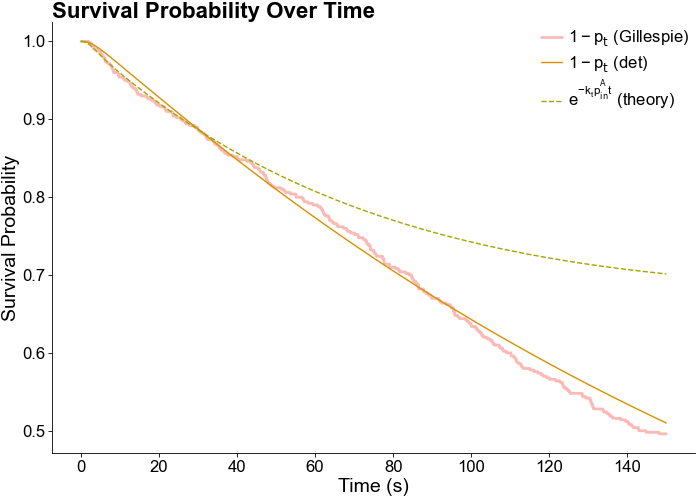

In [ ]:
# Plotting the results
plt.figure()
plt.plot(t_gillespie, p_in_A_gillespie, alpha=0.5, label=r'$p_{\text{in}}^{\text{A}}$')
plt.plot(t_gillespie, p_in_N_gillespie, alpha=0.5, label=r'$p_{\text{in}}^{\text{N}}$')
plt.plot(t_gillespie, p_out_A_gillespie, alpha=0.5, label=r'$p_{\text{out}}^{\text{A}}$')
plt.plot(t_gillespie, p_out_N_gillespie, alpha=0.5, label=r'$p_{\text{out}}^{\text{N}}$')
plt.plot(t_gillespie, p_t_gillespie, alpha=0.5, label=r'$p_{\text{t}}$')

plt.plot(t_euler, p_in_A_euler, color=colors[0], lw=1, label=r'$p_{\text{in}}^{\text{A}}$ (det)')
plt.plot(t_euler, p_in_N_euler, color=colors[1], lw=1, label=r'$p_{\text{in}}^{\text{N}}$ (det)')
plt.plot(t_euler, p_out_A_euler, color=colors[2], lw=1, label=r'$p_{\text{out}}^{\text{A}}$ (det)')
plt.plot(t_euler, p_out_N_euler, color=colors[3], lw=1, label=r'$p_{\text{out}}^{\text{N}}$ (det)')
plt.plot(t_euler, p_t_euler, color=colors[4], lw=1, label=r'$p_{\text{t}}$ (det)')

plt.xlabel('Time (s)')
plt.ylabel('Probability')
plt.title('Dynamics of Local Probabilities Over Time')

plt.text(0.8, 0.9, f"N particles = {n_particles}", transform=plt.gca().transAxes, fontsize=10, ha='center')

plt.legend(ncol=2)
plt.show()


plt.figure()
plt.plot(t_gillespie, p_in_gillespie, alpha=0.5, label=r'$p_{\text{in}}$', color=colors[4])
plt.plot(t_gillespie, p_out_gillespie, alpha=0.5, label=r'$p_{\text{out}}$', color=colors[5])
plt.plot(t_gillespie, p_A_gillespie, alpha=0.5, label=r'$p^{\text{A}}$', color=colors[6])
plt.plot(t_gillespie, p_N_gillespie, alpha=0.5, label=r'$p^{\text{N}}$', color=colors[7])

plt.plot(t_euler, p_in_euler, color=colors[4], lw=1, label=r'$p_{\text{in}}$ (det)')
plt.plot(t_euler, p_out_euler, color=colors[5], lw=1, label=r'$p_{\text{out}}$ (det)')
plt.plot(t_euler, p_A_euler, color=colors[6], lw=1, label=r'$p^{\text{A}}$ (det)')
plt.plot(t_euler, p_N_euler, color=colors[7], lw=1, label=r'$p^{\text{N}}$ (det)')

plt.xlabel('Time (s)')
plt.ylabel('Probability')
plt.title('Dynamics of Global Probabilities Over Time')

plt.text(0.8, 0.9, f"N particles = {n_particles}", transform=plt.gca().transAxes, fontsize=10, ha='center')
plt.legend(ncol=2)
plt.show()

# Add plot with survival probability
plt.figure()
plt.plot(t_gillespie, 1 - p_t_gillespie, alpha=0.5, label=r'$1 - p_{\text{t}}$ (Gillespie)')
plt.plot(t_euler, 1 - p_t_euler, lw=1, label=r'$1 - p_{\text{t}}$ (det)')
plt.plot(t_euler, np.exp(-absorb * p_in_A_euler * t_euler), lw=1, ls='--', label=r'$e^{-k_t p_{\text{in}}^{\text{A}} t}$ (theory)')
plt.xlabel('Time (s)')
plt.ylabel('Survival Probability')
plt.title('Survival Probability Over Time')
plt.legend()
plt.show()


In [91]:
# Integrate the survival probability over time to get the mean first passage time (MFPT)
mfpt_gillespie = cumulative_trapezoid(1 - p_t_gillespie, t_gillespie, initial=0)
mfpt_euler = cumulative_trapezoid(1 - p_t_euler, t_euler, initial=0)

print(f"MFPT (Gillespie): {mfpt_gillespie[-1]:.4f} s")
print(f"MFPT (Euler): {mfpt_euler[-1]:.4f} s")

MFPT (Gillespie): 39.7547 s
MFPT (Euler): 42.8847 s


In [92]:
# Calculate the theoretical MFPT based on the Backward Kolmogorov equations for the two-state model
activation_outside = 1  # Assuming activation occurs outside the droplet

TA_func, TI_func, out = compute_for_two_state(
        r_target=rt,
        rf=rf,
        rn=rn,
        A=A0,
        b=b,
        D0=D,
        Dn=D,
        lam=activation_rate,
        gamma=deactivation_rate,
        activation_outside=activation_outside,
        ndim=3,
        N=300,
        tol=1e-6,
        max_nodes=20000,
    )
T_A = out["TA_rn"]
T_I = out["TI_rn"]

print(f"Theoretical MFPT (T_A at rn): {T_A:.4f} s")
print(f"Theoretical MFPT (T_I at rn): {T_I:.4f} s")

Theoretical MFPT (T_A at rn): 19.5018 s
Theoretical MFPT (T_I at rn): 19.5218 s


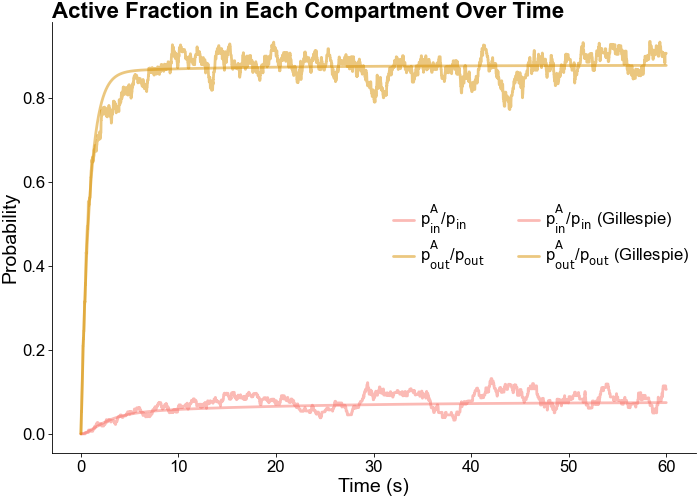

In [64]:
# Plot the active fraction in each compartment as a function of time

plt.figure()
plt.plot(t_euler, p_in_A_euler / p_in_euler, alpha=0.5, label=r'$p_{\text{in}}^{\text{A}} / p_{\text{in}}$', color=colors[0])
plt.plot(t_euler, p_out_A_euler / p_out_euler, alpha=0.5, label=r'$p_{\text{out}}^{\text{A}} / p_{\text{out}}$', color=colors[1])

plt.plot(t_gillespie, p_in_A_gillespie / p_in_gillespie, alpha=0.5, label=r'$p_{\text{in}}^{\text{A}} / p_{\text{in}}$ (Gillespie)', color=colors[0])
plt.plot(t_gillespie, p_out_A_gillespie / p_out_gillespie, alpha=0.5, label=r'$p_{\text{out}}^{\text{A}} / p_{\text{out}}$ (Gillespie)', color=colors[1])

plt.xlabel('Time (s)')
plt.ylabel('Probability')
plt.title('Active Fraction in Each Compartment Over Time')

plt.legend(ncol=2)
plt.show()